In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("employees.csv")

df.head()


,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR


In [3]:
df.isnull().sum()

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64

In [7]:
df['Age'] = df['Age'].fillna(df['Age'].median())

df['Salary'] = df['Salary'].fillna(df['Salary'].median())

In [10]:
df.isnull().sum()

Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64

In [12]:
df.duplicated().sum()

1

In [14]:
df = df.drop_duplicates()

In [16]:
df.duplicated().sum()

0

In [18]:
df['Name'] = df['Name'].str.strip()

df['Department'] = df['Department'].str.strip()

In [20]:
df['Name'] = df['Name'].str.lower()

df['Department'] = df['Department'].str.lower()

In [22]:
df.head()

,Name,Age,Salary,Join_Date,Department
0,pam,25.0,70200.0,1/15/2023,hr
1,jane,36.0,65000.0,8/1/2022,finance
2,alice,22.0,71350.0,5/20/2021,hr
3,bob,22.0,71841.0,1/15/2023,it
4,pam,25.0,71250.0,1/15/2023,hr


In [24]:
df['Salary'].describe()

count        42.000000
mean     124031.309524
std      183008.178720
min       61000.000000
25%       68500.000000
50%       71841.000000
75%       77421.000000
max      921000.000000
Name: Salary, dtype: float64

In [26]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: 55118.5
Upper limit: 90802.5


In [28]:
outliers = df[
    (df['Salary'] < lower_limit) |
    (df['Salary'] > upper_limit)
]

outliers[['Name', 'Salary', 'Department']]

,Name,Salary,Department
6,joanne,120000.0,it
15,susy,126001.0,it
18,joanne,125600.0,it
21,norma,921000.0,it
28,jenny,801423.0,it
42,kim,546222.0,hr


In [30]:
df['Salary'] = df['Salary'].clip(
    lower=lower_limit,
    upper=upper_limit
)

In [32]:
df['Salary'].describe()

count       42.000000
mean     74140.095238
std       8506.656349
min      61000.000000
25%      68500.000000
50%      71841.000000
75%      77421.000000
max      90802.500000
Name: Salary, dtype: float64

In [34]:
df['Join_Date'] = pd.to_datetime(
    df['Join_Date'],
    format='%m/%d/%Y'
)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42 entries, 0 to 42
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Name        42 non-null     object        
 1   Age         42 non-null     float64       
 2   Salary      42 non-null     float64       
 3   Join_Date   42 non-null     datetime64[ns]
 4   Department  42 non-null     object        
dtypes: datetime64[ns](1), float64(2), object(2)
memory usage: 2.0+ KB


In [38]:
df = pd.get_dummies(
    df,
    columns=['Department'],
    dtype=int
)

df.head()

,Name,Age,Salary,Join_Date,Department_finance,Department_hr,Department_it
0,pam,25.0,70200.0,2023-01-15,0,1,0
1,jane,36.0,65000.0,2022-08-01,1,0,0
2,alice,22.0,71350.0,2021-05-20,0,1,0
3,bob,22.0,71841.0,2023-01-15,0,0,1
4,pam,25.0,71250.0,2023-01-15,0,1,0


In [40]:
df.to_csv('cleaned_employees.csv', index=False)

In [42]:
import os

print(os.path.exists('cleaned_employees.csv'))

True


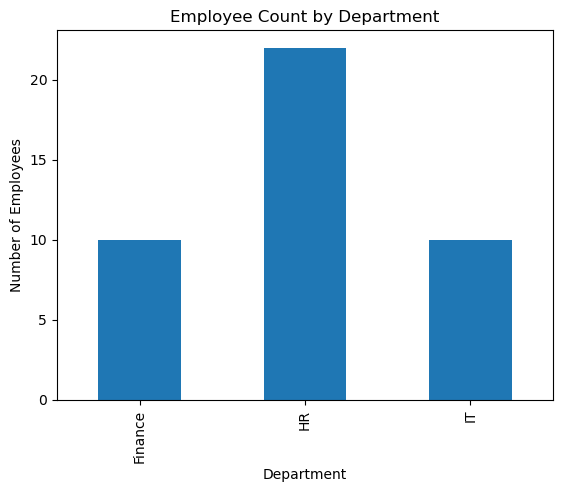

In [44]:
department_counts = df[
    ['Department_finance', 'Department_hr', 'Department_it']
].sum()

department_counts.index = ['Finance', 'HR', 'IT']

department_counts.plot(kind='bar', title='Employee Count by Department')

plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.show()

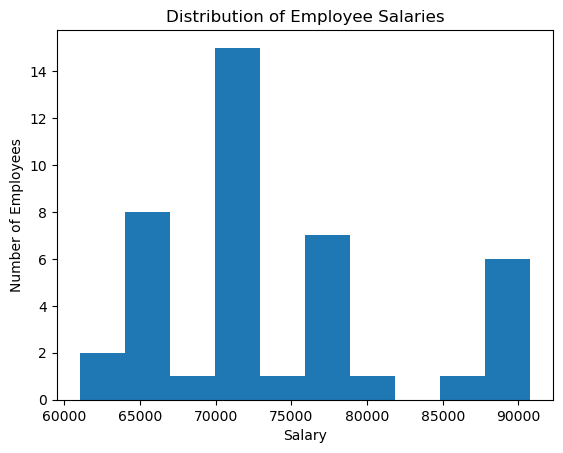

In [46]:

df['Salary'].plot(kind='hist', title='Distribution of Employee Salaries', bins=10)

plt.xlabel('Salary')
plt.ylabel('Number of Employees')
plt.show()


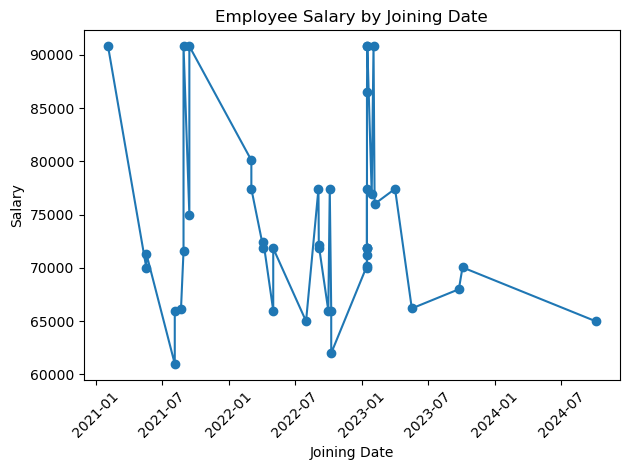

In [48]:

df_sorted = df.sort_values('Join_Date')

plt.plot(df_sorted['Join_Date'], df_sorted['Salary'], marker='o')

plt.title('Employee Salary by Joining Date')
plt.xlabel('Joining Date')
plt.ylabel('Salary')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


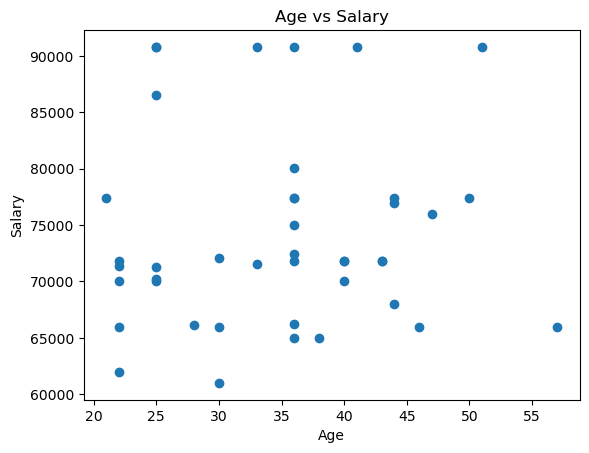

In [50]:

plt.scatter(df['Age'], df['Salary'])

plt.title('Age vs Salary')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()


In [52]:

print(df.head())
print(df.info())
print(df.isnull().sum())


    Name   Age   Salary  Join_Date  Department_finance  Department_hr  \
0    pam  25.0  70200.0 2023-01-15                   0              1   
1   jane  36.0  65000.0 2022-08-01                   1              0   
2  alice  22.0  71350.0 2021-05-20                   0              1   
3    bob  22.0  71841.0 2023-01-15                   0              0   
4    pam  25.0  71250.0 2023-01-15                   0              1   

   Department_it  
0              0  
1              0  
2              0  
3              1  
4              0  
<class 'pandas.core.frame.DataFrame'>
Index: 42 entries, 0 to 42
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Name                42 non-null     object        
 1   Age                 42 non-null     float64       
 2   Salary              42 non-null     float64       
 3   Join_Date           42 non-null     datetime64[ns]
 4   Departmen

In [54]:
df = df.reset_index(drop=True)
df.to_csv('cleaned_employees.csv', index=False)